Dataset dimensions: (920, 17)
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
 16  target    920 non-null    int64  
dtypes: float64(5), int64(4), object(2), str(6)
memory usage: 420.8 KB
Total Memory: 0.41 MB
<class 'pandas.DataFrame'>
RangeIndex: 920

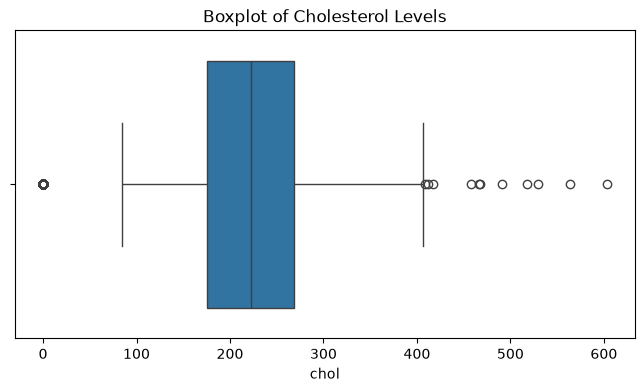

In [1]:
#step 1:data inspection and structure analysis
import pandas as pd
import numpy as np
df=pd.read_csv('heart_disease_dataset.csv')
#before doing anything:the target values are 0,1,2... the number of heart attacks so we need to convert them to binary values 0 and 1 so we will consider the values of 0 as no heart attack and the values of 1,2,3,4 as heart attack so we will convert them to 1
df['target'] = df["num"].apply(lambda x: 1 if x > 0 else 0)
df_clean=df.drop(columns=['num'])
#also there is one important thing we need to know is how to determine the correlation between the categorical features and the target variable so we will use chi-square(look code 2)
#1:check dimension of the dataset
print("Dataset dimensions:", df.shape)
#this check will tell us how many rows and columns are present in the dataset and if we are dealing with a large dataset or not
#if we are dealing with a large dataset we will have to use some techniques to optimize the memory usage of the dataset
#how to know the memory usage of the dataset?-->
df.info(memory_usage='deep')
#how to know the total memory usage of the dataset?-->
print(f"Total Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
#always we need 30-50% of the total memory to work with the dataset

#2:inspect data types and non-null counts of the dataset
df.info()
#this check will tell us the data types of each column and how many non-null values are present in each column
#the goal:ensure that the data types of each column are appropriate for the type of data they contain and to check for any missing values in the dataset
#so we need to know the percentege of missing values in each column of the dataset
missing_summary=pd.DataFrame({'Missing Count': df.isnull().sum(), 'Missing Percentage': df.isnull().sum()/len(df)*100})
print(missing_summary)
#ok now we need to handle missing values in the dataset
#so we have 4 ranges:<5% ,5-20%,20-50%,>50%
#i will start with <5% missing values
#here we have 3 strategies to handle missing values:
#u can see them in the documentation
#now i will use Simple Mean / Median Imputation 
#but how to know which one to use mean or median?
#we need to see if we have outliers in the dataset or not
#how to check for outliers in the dataset?-->
#using boxplot

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,4))
sns.boxplot(x=df['chol'])
plt.title('Boxplot of Cholesterol Levels')
plt.show()
#so the boxplot shows us that we have outliers in the dataset   
#first the 0 values are not valid for cholesterol levels so we need to replace them with NaN values
df['chol'] = pd.to_numeric(df['chol'], errors='coerce')  # Convert to numeric, coercing errors to NaN
df.loc[df['chol'] <= 0, 'chol'] = np.nan
#and the other values that are more than 300 are also outliers so we need to replace them with a cap value of 300
df['chol'] = df['chol'].clip(upper=300)
#now we can use median imputation to handle the missing values in the 'chol' column
chol_median = df['chol'].median()
df['chol']=df['chol'].fillna(chol_median)

#ok now i pass to the next column which is 'restecg' and it has  0.217% missing values so we will just drop the rows with missing values in this column 
df.dropna(subset=['restecg'], inplace=True)
#ok now  i pass to columns that have more than 5% missing values and less than 20% missing values which are 'trestbps','thalach','fbs','exang', and 'oldpeak' columns
#so here also we have 3 strategies to handle missing values:
#u can see them in the documentation
#each one depend on the context of the dataset and the type of data we have in each column
#now i will use Model-Based Imputation 
#and specially MICE
#what is MICE?-->
#MICE stands for Multiple Imputation by Chained Equations. It treats every column with missing values as a target variable and loops through them iteratively. It builds a regression or classification model for each column using all other columns, updating the missing cells in rounds until the values stabilize.
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
#but before that we need to check the data types of the columns that have missing values and convert them to numeric if they are not numeric
impute_cols = ['trestbps', 'thalch', 'fbs', 'exang', 'oldpeak']
for col in impute_cols:
    if df[col].dtype == 'object':
        df[col] = pd.to_numeric(df[col], errors='coerce')  
#we found that the 'fbs' and 'exang' columns are of object type(boolean) so we need to convert them to numeric type
#now i will create an instance of the IterativeImputer class
imputer = IterativeImputer(max_iter=10, random_state=42)
#now i will fit the imputer to the selected columns
df[impute_cols] = imputer.fit_transform(df[impute_cols])
#post-processing: after imputation, we need to round the values of 'fbs' and 'exang' columns to the nearest integer and convert them back to float type
df['fbs'] = df['fbs'].round().astype(float)
df['exang'] = df['exang'].round().astype(float)

#ok now i pass to the columns that have more than 20% missing values and less than 50% missing values which is 'slope' column
#so here also we have 2 strategies to handle missing values:
#u can see them in the documentation
#and bcz the slope is a categorical column so we will use the most frequent technique for categorical features
#is called Explicit "Missing" Category 
#what is Explicit "Missing" Category?-->
#replace missing string/category values with a dedicated label like 'Missing'
df['slope'] = df['slope'].fillna('Missing')
#now i pass to the columns that have more than 50% missing values which is 'ca' and 'thal' columns
#i will start first with 'thal' which is a categorical column represents a test so in easy way the null comlumns they are patients that didn't do the test so we will replace the missing values with a dedicated label like 'Not Tested'
df['thal'] = df['thal'].fillna('Not Tested')
#for the ca also as it's a categorical column represents a test so in easy way the null comlumns they are patients that didn't do the test so we will replace the missing values with a dedicated label like -1
df['ca'] = df['ca'].fillna(-1)


In [2]:
from scipy.stats import chi2_contingency
import pandas as pd
cotingency_table = pd.crosstab(df['ca'], df['target'])
chi2, p, dof, expected = chi2_contingency(cotingency_table)
print(f"Chi-square statistic: {chi2}, p-value: {p}")

Chi-square statistic: 87.68694589960924, p-value: 4.080570354192763e-18


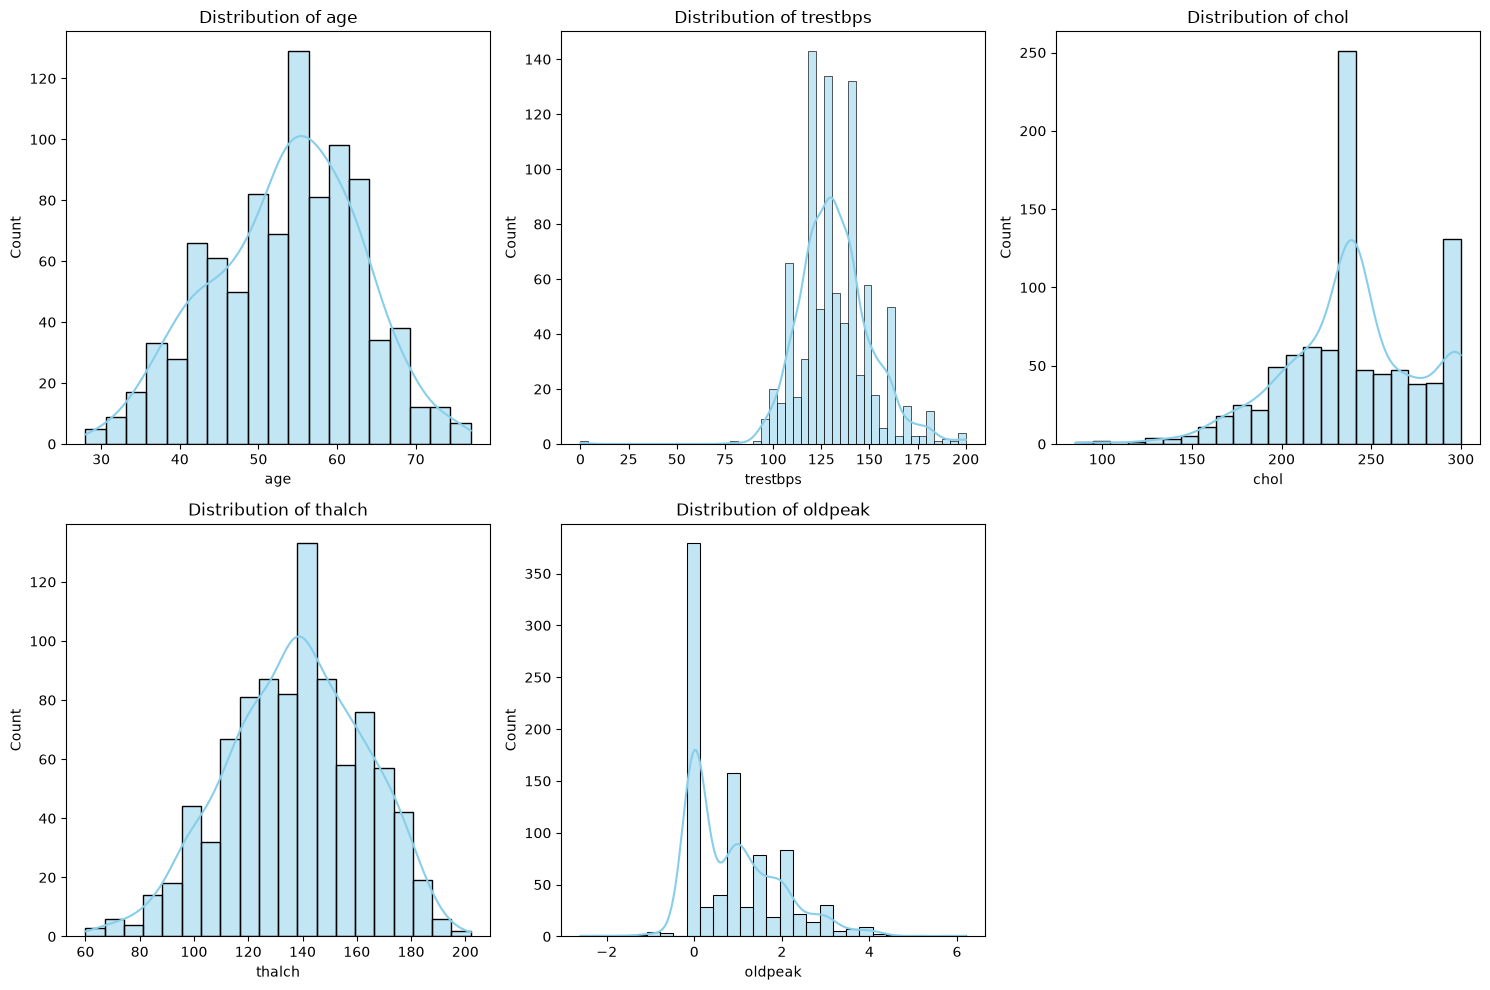

Skewness of numerical features:
age        -0.193710
trestbps    0.196644
chol       -0.351275
thalch     -0.208429
oldpeak     1.063805
dtype: float64


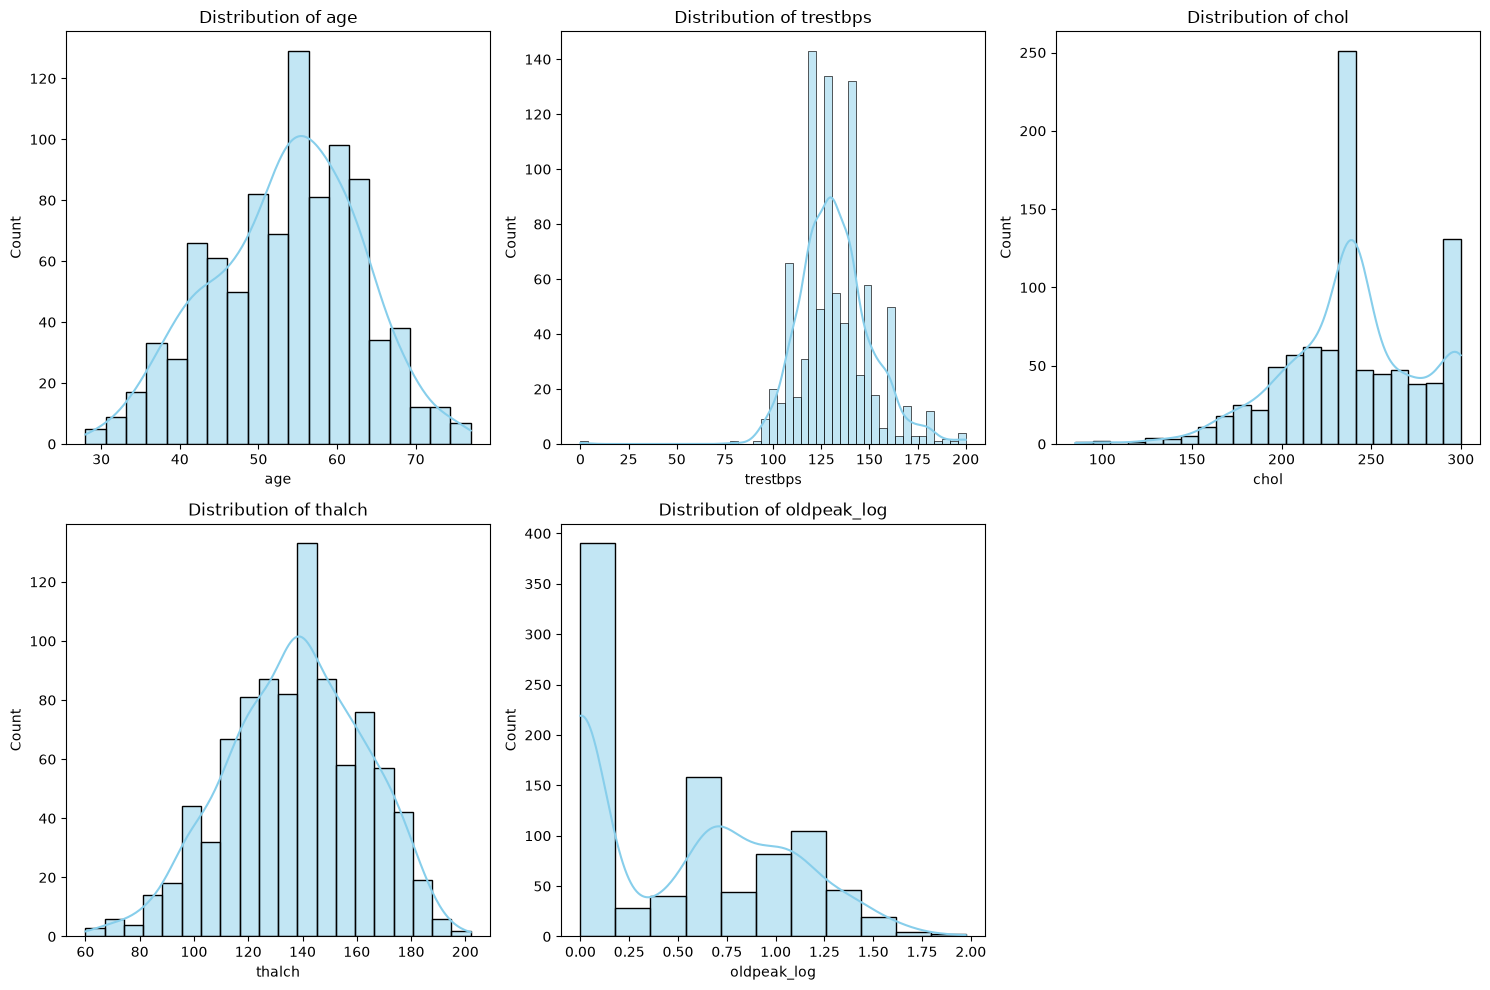

Skewness of numerical features:
age           -0.193710
trestbps       0.196644
chol          -0.351275
thalch        -0.208429
oldpeak_log    0.409337
dtype: float64
Class distribution of categorical features:

Feature:sex
        Counts  Percentage
sex                       
Male       724       78.87
Female     194       21.13

Feature:cp
                 Counts  Percentage
cp                                 
asymptomatic        495       53.92
non-anginal         204       22.22
atypical angina     174       18.95
typical angina       45        4.90

Feature:fbs
     Counts  Percentage
fbs                    
0.0     780       84.97
1.0     138       15.03

Feature:restecg
                  Counts  Percentage
restecg                             
normal               551       60.02
lv hypertrophy       188       20.48
st-t abnormality     179       19.50

Feature:exang
       Counts  Percentage
exang                    
0.0       580       63.18
1.0       338       36.82

Feature:s

In [3]:
#Step 2:Exploratory Data Analysis (EDA) and Feature Engineering
#Phase 1: Univariate Analysis
#here we will analyze each feature individually
#for numerical features we will inspect variables to check if they follow a normal distribution or are heavily skewed
#what does heavily skewed mean?-->
#When a variable is heavily skewed, its data values are not evenly distributed around the mean. Instead, most data points cluster on one side

num_cols=['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
plt.figure(figsize=(15, 10))
for i,col in enumerate(num_cols,1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True,color='skyblue')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

print("Skewness of numerical features:")
print(df[num_cols].skew())
#if the skewness is greater than 1 or less than -1, the feature is highly skewed. If the skewness is between -1 and -0.5 or between 0.5 and 1, the feature is moderately skewed. If the skewness is between -0.5 and 0.5, the feature is approximately symmetric.
#why we use skewness?-->
#first it has influence on the model algorithms and their performance
#Linear models (Logistic Regression, Linear SVM, Neural Networks) perform poorly on heavily skewed features. If skewness is high, apply a Log Transformation
#Tree-Based Models: If you use Tree algorithms (Random Forest, XGBoost), skewness doesn't hurt them
#but what's log transformation?-->
#Log transformation is a mathematical operation that applies the logarithm function to each value in a dataset
#x'=log(x)
#example log(10)=2.30
#also the skewness help in deciding which feature scaling technique to use
#StandardScaler (Z-Score Standardization): Best used when features are roughly normally distributed (bell-shaped)
#RobustScaler: Best used when features are heavily skewed or contain extreme high values
#MinMaxScaler: Rescales values between 0 and 1, best used when features have bounded ranges and minimal skewness.
#so now i will log transform the 'oldpeak' 

import numpy as np
df['oldpeak'] = df['oldpeak'].clip(lower=0)
df['oldpeak_log'] = np.log1p(df['oldpeak'])
df=df.drop(columns=['oldpeak'])
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak_log']
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

print("Skewness of numerical features:")
print(df[num_cols].skew())

#now we pass to the categorical features
#here we don't measure skewness but we look for Class Imbalance or we can say Dominant Categories
#so a feature is considered heavily imbalanced if one category represents more than 90% of the total observations
#let's first check the categorical features in the dataset
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
print("Class distribution of categorical features:")
for col in cat_cols:
    print(f"\nFeature:{col}")
    percentage=df[col].value_counts(normalize=True) * 100
    counts = df[col].value_counts()
    summary_df = pd.DataFrame({'Counts': counts, 'Percentage': percentage.round(2)})
    print(summary_df)
#interpretation: if we have a feature that has a category that represents 85%-90% of the total observations, we can say that this feature is heavily imbalanced 
#the actionable decision:
#<85%: No action needed
#85%-90%:here we need to monitor feature importance during model evaluation(we will see later on)
#>90%: drop column
#in this dataset we don't have any categorical feature that is heavily imbalanced so we don't need to take any action

C:\Users\ASUS\AppData\Local\Temp\ipykernel_15296\3867732781.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=col, data=df, palette=['#2ecc71', '#e74c3c'],width=0.4)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_15296\3867732781.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=col, data=df, palette=['#2ecc71', '#e74c3c'],width=0.4)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_15296\3867732781.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=col, data=df, palette=['#2ecc71', '#e74c3c'],width=0.4

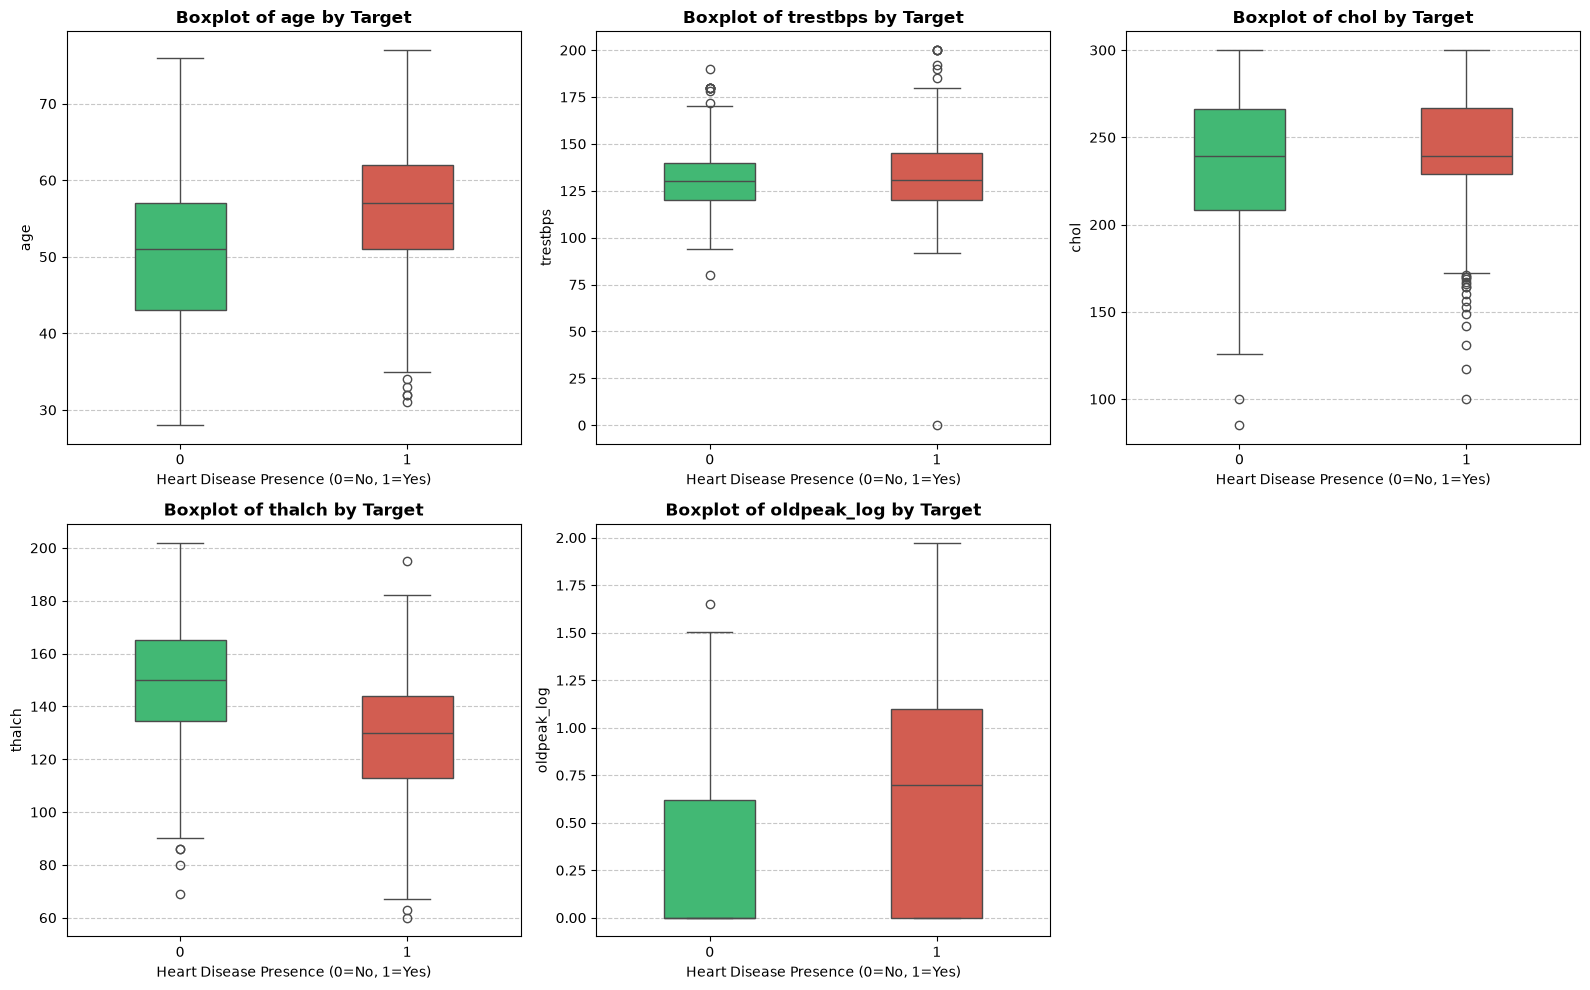

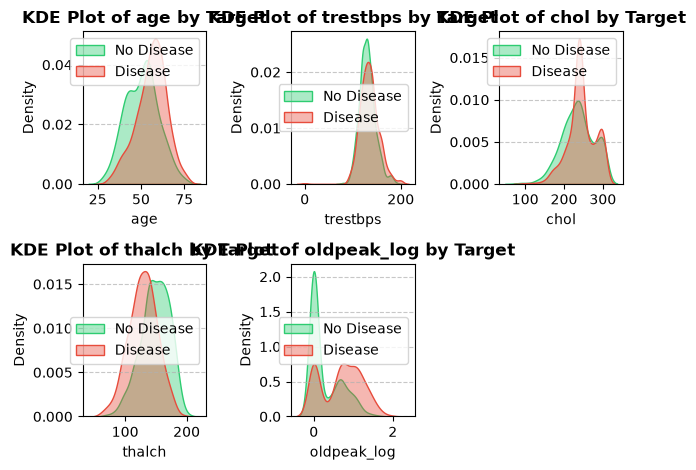


Mann-Whitney U Test Results for Numerical Features:
    Feature  Group 0 Median  Group 1 Median  Mann-Whitney U Statistic  p-value  Significant(p<0.05)
        age            51.0           57.00                   68804.0 0.000000                  Yes
     thalch           150.0          130.00                  151351.0 0.000000                  Yes
oldpeak_log             0.0            0.70                   56543.5 0.000000                  Yes
   trestbps           130.0          130.91                   90375.0 0.000521                  Yes
       chol           239.5          239.50                   91456.0 0.001344                  Yes


In [4]:
#Step 2:Exploratory Data Analysis (EDA) and Feature Engineering
#Phase 1: Bivariate Analysis
#so here we will analyze the relationship between each feature and the target variable
#we focus on evaluating how each independent feature interacts with the target variable
#objectives:
#1: Identify features that have a strong relationship with the target variable(or with other features), which can be useful
#2: Detect redundant features that may not contribute much to the model's predictive power so it's better if we drop them or de-prioritize them
#3:Guide engineering decisions:Reveal linear or non-linear relationships that inform feature transformations or algorithm selection
#we have 3 types of bivariate analysis: 
#1:Contingous vs Binary(numerical vs target)
#2:Categorical vs Binary(categorical vs target)
#3:Continous vs Continous(Feature vs Feature)
#let's start with the first type which is Contingous vs Binary(numerical vs target)
#goal:Compare the distributions of numerical features across the two classes of the target variable
#step1:visual inspection: we will use boxplots and overlaid distribution
#we use boxplots to compare medians,interquartile ranges(IQR), and potential outliers between the two classes
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak_log']
plt.figure(figsize=(16,10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='target', y=col, data=df, palette=['#2ecc71', '#e74c3c'],width=0.4)
    plt.title(f'Boxplot of {col} by Target', fontsize=12, fontweight='bold')
    plt.xlabel('Heart Disease Presence (0=No, 1=Yes)')
    plt.ylabel(col)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
#this boxplot shows us the distribution of each numerical feature across the two classes of the target variable
#and determine the seperation degree between the two classes for each feature
#for our dataset we can see that the 'thalch' and 'oldpeak_log' features show a more pronounced separation between the two classes
#and the others show less distinct separation.
#how we can read the boxplot?-->
#for each boxplot,we have the median line,if the 2 median lines are far apart(have a large gap),it indicates a strong separation between the two classes for that feature
#now we pass to the second technique which is overlaid KDE plots
#what is KDE plot?-->
#Think of a KDE plot as a smoothed-out histogram. Instead of bars, it draws a continuous curve representing where the data points are most densely clustered
#we have 2 results
#high Overlap: if the green curve(no disease and red curve(disease) sit right on top of each other,the feature cannot easily tell the two groups apart
#low overlap: if the curves are pulled apart (one peaks low, one peaks high), the feature provides a sharp boundary for classification algorithms
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.kdeplot(data=df[df['target'] == 0], x=col, fill=True, color='#2ecc71', alpha=0.4, label='No Disease')
    sns.kdeplot(data=df[df['target'] == 1], x=col, fill=True, color='#e74c3c', alpha=0.4, label='Disease')
    plt.title(f'KDE Plot of {col} by Target', fontsize=12, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
#we found that the 'thalch' and 'oldpeak_log' have strong separation(low overlap)
#the age feature shows moderate separation(moderate overlap)
#the 'trestbps' and 'chol' features show weak separation(high overlap)

#now after primary visualization we pass to statistical tests
#we have genrally 2 types of statistical tests:
#Two-Sample T-Test: used when the distributions are normal
#Mann-Whitney U Test: used when the distributions are not normal/skewed
#for our dataset we will use the Mann-Whitney U Test
#to make it simple,imagine you want to know if basketball players are generally taller than soccer players
#the old way: you add up all the basketball players' heights and divide by how many there are. But imagine one basketball player is 7 feet tall,that one giant person will pull the average way up and make the math messy
#the Mann-Whitney U Test way:
#1:You take all the basketball players and all the soccer players, throw them into one big group, and line everyone up from shortest to tallest
#2:Then, you look at where the players are standing in that line
#3:If you notice that almost all the basketball players are standing near the tall end of the line, and almost all the soccer players are standing near the short end, you can safely say: "Yes, basketball players are genuinely taller.
#How to apply this in our dataset?-->
#When we run the Mann-Whitney U Test on a feature like thalch
#1:We take the max heart rates of all healthy people and all heart disease patients and line them up from lowest to highest
#2:The test checks: Are the healthy people consistently landing higher up in the line, while heart disease patients land lower down?
#3:It gives us a score (p-value). If the groups are separated enough in that line, the test says, "This feature is a powerful predictor—it's not just random luck."
from scipy.stats import mannwhitneyu
num_results = []
for col in num_cols:
    group0 = df[df['target'] == 0][col]
    group1 = df[df['target'] == 1][col]
    stat, p_value = mannwhitneyu(group0, group1, alternative='two-sided')
    num_results.append({'Feature': col, 'Group 0 Median': round(group0.median(), 2), 'Group 1 Median': round(group1.median(), 2), 'Mann-Whitney U Statistic': round(stat, 2), 'p-value': round(p_value,6),' Significant(p<0.05)': 'Yes' if p_value < 0.05 else 'No'})
num_analysis_df = pd.DataFrame(num_results).sort_values(by='p-value')
print("\nMann-Whitney U Test Results for Numerical Features:")
print(num_analysis_df.to_string(index=False))
#so we notice that all the 5 numerical features are statistically valid predictors andwe should be keep them for the next steps

In [5]:
#Step 2:Exploratory Data Analysis (EDA) and Feature Engineering
#Phase 1: Bivariate Analysis
#2:Categorical vs Binary(categorical vs target)
#here we will use the Chi-Square Test of Independence to determine if there is a significant association between each categorical feature and the target variable
#we have 2 results:
#the null hypothesis(H0): there is no association between the categorical feature and the target variable
#the alternative hypothesis(H1): there is an association between the categorical feature and the target variable
#why it matters?-->
#If p<0.05, we reject the null hypothesis and conclude that there is a significant association between the categorical feature and the target variable

from scipy.stats import chi2_contingency
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
chi2_results = []
for col in cat_cols:
    contingency_table = pd.crosstab(df[col], df['target'])
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    chi2_results.append({'Feature': col, 'Chi-square Statistic': round(chi2, 2), 'degrees of Freedom': dof, 'p-value': round(p, 6), 'Significant(p<0.05)': 'Yes' if p < 0.05 else 'No'})
chi2_analysis_df = pd.DataFrame(chi2_results).sort_values(by='p-value')
print("\nChi-Square Test Results for Categorical Features:")
print(chi2_analysis_df.to_string(index=False))
#so we notice that all the 8 categorical features are statistically valid predictors and we should be keep them for the next steps


Chi-Square Test Results for Categorical Features:
Feature  Chi-square Statistic  degrees of Freedom  p-value Significant(p<0.05)
    sex                 84.81                   1 0.000000                 Yes
     cp                268.12                   3 0.000000                 Yes
  slope                143.49                   3 0.000000                 Yes
  exang                170.29                   1 0.000000                 Yes
     ca                 87.69                   4 0.000000                 Yes
   thal                109.09                   3 0.000000                 Yes
    fbs                 10.30                   1 0.001327                 Yes
restecg                 11.71                   2 0.002863                 Yes



Correlation Matrix for Numerical Features:
               age  trestbps   chol  thalch  oldpeak_log
age          1.000     0.238  0.092  -0.354        0.279
trestbps     0.238     1.000  0.076  -0.106        0.142
chol         0.092     0.076  1.000  -0.029        0.059
thalch      -0.354    -0.106 -0.029   1.000       -0.183
oldpeak_log  0.279     0.142  0.059  -0.183        1.000


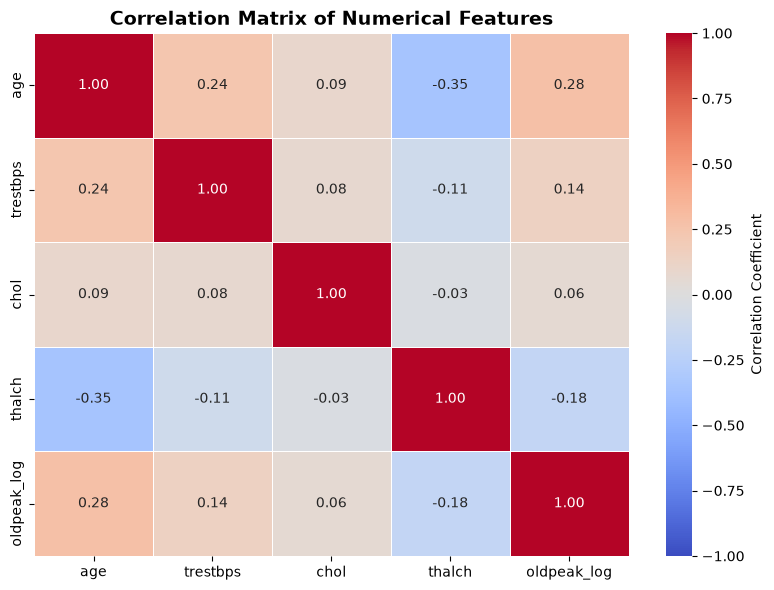

In [6]:
#Step 2:Exploratory Data Analysis (EDA) and Feature Engineering
#Phase 1: Bivariate Analysis
#3:Continous vs Continous(Feature vs Feature)
#the goal: We want to check for multicollinearity—a situation where two or more features carry almost the exact same information (e.g., if we had two columns measuring blood pressure in different units).
#we will use the Correlation Matrix which gives us a score between -1 and 1
#+1: perfect positive correlation (as one feature increases, the other feature increases proportionally)
#0: no linear relationship
#-1: perfect negative correlation (as one feature increases, the other feature decreases proportionally)
#why we use correlation matrix?-->
#1: Identify Redundant Features: If two features are highly correlated (e.g., correlation coefficient > 0.8), they may be redundant. Keeping both can lead to overfitting and increased model complexity.
#2: Model safety:Tree-based models (like Random Forest or XGBoost) handle correlated features fine, but simpler statistical models prefer independent inputs

num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak_log']
corr_matrix = df[num_cols].corr(method='pearson')
print("\nCorrelation Matrix for Numerical Features:")
print(corr_matrix.round(3))
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5,cbar_kws={"label": "Correlation Coefficient"})
plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
#all is good we don't have any highly correlated features so we will keep all the numerical features for the next steps

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
#Step 3:Preprocessing and Encoding
#first we drop the 2 comumns 'id' and 'dataset'
cols_to_drop = ['id', 'dataset']
x = df.drop(columns=[col for col in cols_to_drop if col in df.columns])
y=df['target']
#phase 2:train test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
#now we need to define the columns list
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak_log']
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
#here we have 2 important steps to do:
#1:Feature Scaling for numerical features
#2:One-Hot Encoding for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first',handle_unknown='ignore'), cat_cols)
    ])
#we transform the data to what we transform
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)
print("Preprocessing completed. The training and testing datasets are now ready for model training.")
print(f"Training set shape: {x_train_processed.shape}, Testing set shape: {x_test_processed.shape}")

Preprocessing completed. The training and testing datasets are now ready for model training.
Training set shape: (734, 23), Testing set shape: (184, 23)


In [ ]:
#step4:now model training and baseline evaluation
#actually this is the most important step in the whole process of building a machine learning model
#since we have a binary classification problem, we want to train a few baseline models,compare their performance, and select the best one for further tuning and optimization
#the models are:logistic regression,random forest classifier,XGBoost classifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
modles = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss')
}

for model_name, model in modles.items():
    print(f"\nModel: {model_name}")
    model.fit(x_train_processed, y_train)
    y_pred = model.predict(x_test_processed)
    y_proba = model.predict_proba(x_test_processed)[:, 1]
    accuracy = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"ROC AUC Score: {roc_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("="*50)
#i will choose random forest classifier 


Model: Logistic Regression
Accuracy: 0.8478
ROC AUC Score: 0.9248

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.76      0.82        82
           1       0.82      0.92      0.87       102

    accuracy                           0.85       184
   macro avg       0.86      0.84      0.84       184
weighted avg       0.85      0.85      0.85       184


Model: Random Forest
Accuracy: 0.8533
ROC AUC Score: 0.9087

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.78      0.83        82
           1       0.84      0.91      0.87       102

    accuracy                           0.85       184
   macro avg       0.86      0.85      0.85       184
weighted avg       0.86      0.85      0.85       184


Model: XGBoost
Accuracy: 0.8424
ROC AUC Score: 0.8796

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.76   

C:\Users\ASUS\AppData\Roaming\Python\Python312\site-packages\xgboost\training.py:200: UserWarning: [08:06:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Starting hyperparameter tuning using GridSearchCV...

Best Hyperparameters found:
{'max_depth': 6, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
--------------------------------------------------
Tuned Model Accuracy: 0.8641
Tuned Model ROC AUC: 0.9193

Classification Report for Tuned Model:
              precision    recall  f1-score   support

           0       0.90      0.78      0.84        82
           1       0.84      0.93      0.88       102

    accuracy                           0.86       184
   macro avg       0.87      0.86      0.86       184
weighted avg       0.87      0.86      0.86       184



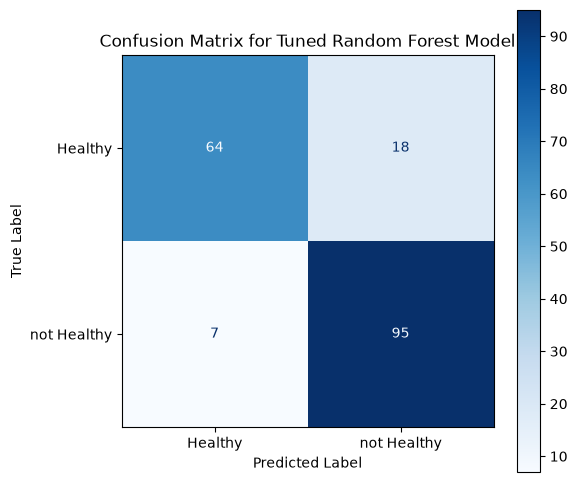

In [17]:
#step5:Hyperparameter tuning and model optimization
#so when we trained our baseline models, we used the default hyperparameters provided by the libraries
#tuning means systematically testing different combinations of settings to find the best configuration that gives our model the best performance
#1:Defining the Parameter Grid
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
param_grid = {
    'n_estimators': [100, 200, 300],#number of trees in the forest
    'max_depth': [None, 6,8,10,15],#maximum depth of each tree
    'min_samples_split': [2, 5],#minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2],#minimum number of samples required to be at a leaf node
}
rf=RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
print("Starting hyperparameter tuning using GridSearchCV...")
grid_search.fit(x_train_processed, y_train)
print("\nBest Hyperparameters found:")
print(grid_search.best_params_)
print("-"*50)
best_rf=grid_search.best_estimator_
y_pred_tuned=best_rf.predict(x_test_processed)
y_proba_tuned=best_rf.predict_proba(x_test_processed)[:, 1]

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_roc_auc = roc_auc_score(y_test, y_proba_tuned)
print(f"Tuned Model Accuracy: {tuned_accuracy:.4f}")
print(f"Tuned Model ROC AUC: {tuned_roc_auc:.4f}")
print("\nClassification Report for Tuned Model:")
print(classification_report(y_test, y_pred_tuned))

# Display the confusion matrix for the tuned model
cm = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Healthy', 'not Healthy'])
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=plt.gca())
plt.title('Confusion Matrix for Tuned Random Forest Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.grid(False)
plt.show()

Starting hyperparameter tuning using GridSearchCV...

Best Hyperparameters found:
{'max_depth': 6, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
--------------------------------------------------
Tuned Model Accuracy: 0.8641
Tuned Model ROC AUC: 0.9193

Classification Report for Tuned Model:
              precision    recall  f1-score   support

           0       0.90      0.78      0.84        82
           1       0.84      0.93      0.88       102

    accuracy                           0.86       184
   macro avg       0.87      0.86      0.86       184
weighted avg       0.87      0.86      0.86       184

